Importing the data


In [1]:
import pandas as pd

df_dta = pd.read_stata('Microdata/vup_s0_s1_s2_s3_s4_s6a_s6b_s6c_person.dta')
df_dta.to_csv('nisr_vup_demographics.csv', index=False)

C:\Users\irige\AppData\Local\Temp\ipykernel_26356\1962569811.py:3: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  df_dta = pd.read_stata('Microdata/vup_s0_s1_s2_s3_s4_s6a_s6b_s6c_person.dta')


Filtering the youth.


In [2]:
import pandas as pd

df = pd.read_csv('nisr_vup_demographics.csv')

#filter for youth 16 to 30years old
df['s1q3y'] = pd.to_numeric(df['s1q3y'], errors='coerce')
df_youth = df[(df['s1q3y'] >= 16) & (df['s1q3y'] <= 30)].copy()

Select the earnings(s6bq1) as a target and dropping youth without listed income
And keeping only features or columns for my model
Function to normalize to monthly income

In [3]:
df_youth['s6bq9a'] = pd.to_numeric(df_youth['s6bq9a'], errors='coerce')
df_clean = df_youth.dropna(subset=['s6bq9a', 's6bq9b']).copy()


def normalize_to_monthly(row):
    amount = row['s6bq9a']
    unit = str(row['s6bq9b']).strip().upper() 
    
    if 'HOUR' in unit: return amount * 8 * 22 
    elif 'DAY' in unit: return amount * 22
    elif 'WEEK' in unit: return amount * 4.33
    elif 'FORTNIGHT...4' in unit: return amount * 2
    elif 'MONTH.' in unit: return amount
    elif 'QUARTER' in unit: return amount / 3
    elif 'YEAR.' in unit: return amount / 12
    else: return None


df_clean['monthly_income'] = df_clean.apply(normalize_to_monthly, axis=1)
df_clean = df_clean.dropna(subset=['monthly_income']).copy()

target = 'monthly_income'

features = ['s1q3y', 's1q2', 'ur', 'province', 'poverty', 's4aq7', 'quintile']

df_final = df_clean[features + [target]].dropna().copy()

# CRITICAL FIX: Cast Age back to a continuous float so get_dummies ignores it
df_final['s1q3y'] = df_final['s1q3y'].astype(float)

# 5. One-Hot Encoding
df_encoded = pd.get_dummies(df_final, drop_first=True)

print(f"Final usable rows: {df_encoded.shape[0]}")

Final usable rows: 1381


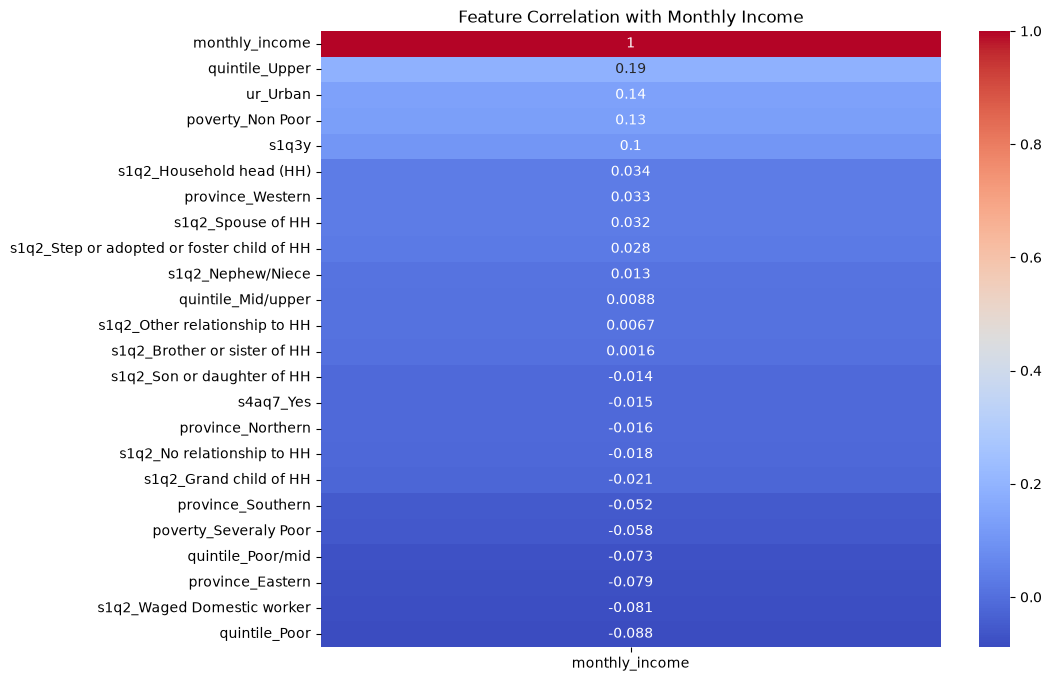

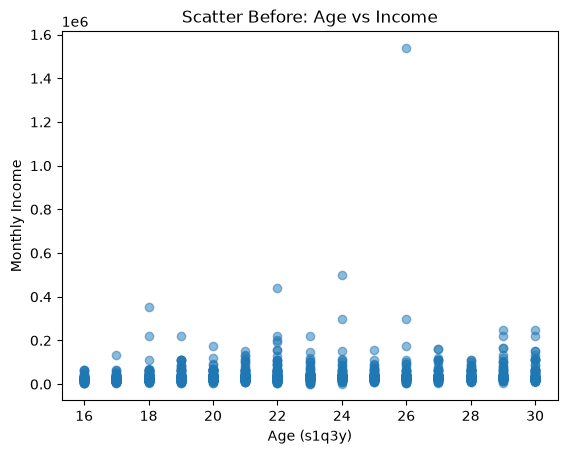

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns


# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_encoded.corr()[['monthly_income']].sort_values(by='monthly_income', ascending=False), annot=True, cmap='coolwarm')
plt.title("Feature Correlation with Monthly Income")
plt.show()

# Target vs Top Feature
plt.scatter(df_encoded['s1q3y'], df_encoded['monthly_income'], alpha=0.5)
plt.xlabel("Age (s1q3y)")
plt.ylabel("Monthly Income")
plt.title("Scatter Before: Age vs Income")
plt.show()

This heatmap reveals that the upper wealth quintile and those living in an Urban area have the strongest positive correlations. And for people like working as a Waged Domestic worker or living in other provinces are negatively correlated with earnings showing regional and occupational wage differences.

This scatterplot of age against income reveals that the vast majority youth from 16-30 are in the lowest income brackeet.

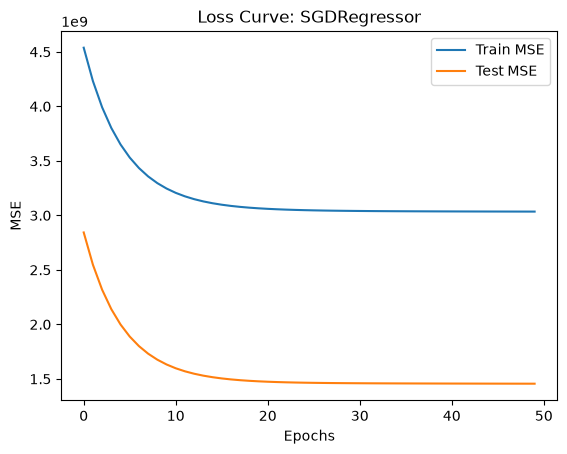

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

X = df_encoded.drop(columns=['monthly_income'])
y = df_encoded['monthly_income']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


sgd = SGDRegressor(learning_rate='constant', eta0=0.0001,random_state=42)
epochs = 50
train_mse, test_mse = [], []

for epoch in range(epochs):
    sgd.partial_fit(X_train_scaled, y_train)
    
    train_mse.append(mean_squared_error(y_train, sgd.predict(X_train_scaled)))
    test_mse.append(mean_squared_error(y_test, sgd.predict(X_test_scaled)))

# Plot Loss Curve
plt.plot(range(epochs), train_mse, label='Train MSE')
plt.plot(range(epochs), test_mse, label='Test MSE')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.title('Loss Curve: SGDRegressor')
plt.legend()
plt.show()

The SGDRegressor loss curve shows both MSE remain very high which suggests that the learning rate is not the right one or the linear model is struggling to map the outliers in the dataset.

In [7]:
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# Initialize the 4 required models
sgd = SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', random_state=42)
lr = LinearRegression()
dt = DecisionTreeRegressor(random_state=42)
rf = RandomForestRegressor(random_state=42)

models = {
    'SGDRegressor': sgd, 
    'LinearRegression': lr, 
    'DecisionTree': dt, 
    'RandomForest': rf
}

# Train and evaluate each
print("--- Model Comparison (Test MSE) ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, predictions)
    print(f"{name}: {mse:,.2f}")

--- Model Comparison (Test MSE) ---
SGDRegressor: 16,323,480,293,918,284.00
LinearRegression: 1,448,310,905.89
DecisionTree: 3,044,911,705.18
RandomForest: 1,969,362,052.04


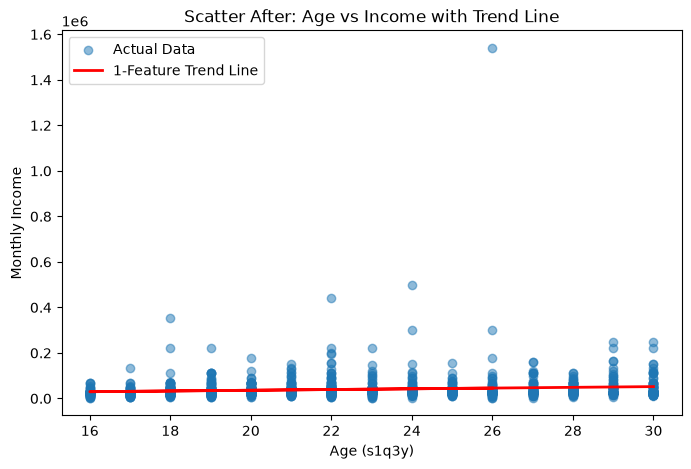

In [8]:
# Train a simple Linear Regression model on just the Age feature
X_train_single = X_train[['s1q3y']]
single_lr = LinearRegression()
single_lr.fit(X_train_single, y_train)

# Re-plot the original scatter
plt.figure(figsize=(8, 5))
plt.scatter(df_encoded['s1q3y'], df_encoded['monthly_income'], alpha=0.5, label='Actual Data')

# Overlay the regression prediction line
plt.plot(X_train_single, single_lr.predict(X_train_single), color='red', linewidth=2, label='1-Feature Trend Line')

plt.xlabel("Age (s1q3y)")
plt.ylabel("Monthly Income")
plt.title("Scatter After: Age vs Income with Trend Line")
plt.legend()
plt.show()

The overlaid 1-feature linear regression line confirms a weak positive relationship between age and monthly income. The trend line remains relatively flat and close to the baseline because the model is heavily anchored by the massive concentration of low-income earners across all age brackets, demonstrating that age alone is a poor predictor for the extreme high-income outliers.